# Notebook 5: Final Evaluation

## Import Libraries

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
)

## Load Saved Logits and Results

## Recreate the four confidence scores

In [2]:
def msp_score(logits):
    probs = torch.softmax(logits, dim=1)
    return probs.max(dim=1).values.numpy()


def entropy_score(logits):
    probs = torch.softmax(logits, dim=1)

    entropy = -torch.sum(
        probs * torch.log(probs.clamp_min(1e-12)),
        dim=1,
    )

    max_entropy = np.log(logits.shape[1])

    return (
        1 - entropy / max_entropy
    ).numpy()


def margin_score(logits):
    probs = torch.softmax(logits, dim=1)

    top2 = torch.topk(
        probs,
        k=2,
        dim=1,
    ).values

    return (
        top2[:, 0] - top2[:, 1]
    ).numpy()


def energy_score(logits, temperature=1.0):
    return (
        temperature
        * torch.logsumexp(
            logits / temperature,
            dim=1,
        )
    ).numpy()


score_functions = {
    "MSP": msp_score,
    "Entropy": entropy_score,
    "Margin": margin_score,
    "Energy": energy_score,
}

## Calibration and Reliability

In [3]:
def expected_calibration_error(
    logits,
    labels,
    n_bins=15,
):
    probs = torch.softmax(logits, dim=1)

    confidences, predictions = probs.max(dim=1)

    accuracies = predictions.eq(labels)

    bin_edges = torch.linspace(
        0,
        1,
        n_bins + 1,
    )

    ece = torch.tensor(0.0)

    reliability = []

    for i in range(n_bins):
        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        in_bin = (
            (confidences > lower)
            & (confidences <= upper)
        )

        prop = in_bin.float().mean()

        if prop > 0:
            bin_acc = accuracies[
                in_bin
            ].float().mean()

            bin_conf = confidences[
                in_bin
            ].mean()

            ece += (
                torch.abs(bin_conf - bin_acc)
                * prop
            )

            reliability.append({
                "confidence": float(bin_conf),
                "accuracy": float(bin_acc),
                "count": int(in_bin.sum()),
            })

    return float(ece), pd.DataFrame(reliability)

## Risk-Coverage Curve

For normal selective classification:

$$
\text{coverage} = \frac{\text{accepted samples}}{N}
$$

and:

$$
\text{risk} = \frac{\text{errors among accepted samples}}{\text{accepted samples}}
$$

For our research question, we need to extend the definition slightly.

For an ID image:
* **Correct ID prediction** $\rightarrow$ no error
* **Incorrect ID prediction** $\rightarrow$ error

For an OOD image:
* **If the model accepts it** $\rightarrow$ error


In [4]:
def risk_coverage_curve(
    id_scores,
    id_errors,
    ood_scores,
):
    scores = np.concatenate([
        id_scores,
        ood_scores,
    ])

    errors = np.concatenate([
        id_errors,
        np.ones(
            len(ood_scores),
            dtype=int,
        ),
    ])

    order = np.argsort(scores)[::-1]

    errors = errors[order]

    cumulative_errors = np.cumsum(errors)

    accepted = np.arange(
        1,
        len(errors) + 1,
    )

    coverage = accepted / len(errors)

    risk = cumulative_errors / accepted

    return coverage, risk

In [5]:
def aurc(coverage, risk):
    # Convert to numpy arrays
    coverage = np.asarray(coverage)
    risk = np.asarray(risk)
    
    # Sort both arrays based on ascending coverage
    sort_idx = np.argsort(coverage)
    
    return np.trapezoid(risk[sort_idx], coverage[sort_idx])

## Seeded final evaluation

Calibration and risk-coverage metrics are computed independently for seeds 14, 27, and 42.

In [6]:
SEEDS = [14, 27, 42]
LOGIT_DIR = Path("./logits")
RESULT_DIR = Path("./results")
FIGURE_DIR = Path("./results/figures")
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

calibration_rows = []
aurc_rows = []
for seed in SEEDS:
    outputs = {}
    for model_prefix in ("mobilenet", "efficientnet"):
        outputs[model_prefix] = {
            dataset: torch.load(
                LOGIT_DIR / f"{model_prefix}_{dataset}_seed{seed}.pt",
                map_location="cpu",
            )
            for dataset in ("id", "grape", "corn", "nonplant")
        }

    for model_name, model_prefix in [("MobileNetV3-Small", "mobilenet"), ("EfficientNet-B0", "efficientnet")]:
        id_output = outputs[model_prefix]["id"]
        ece, reliability = expected_calibration_error(id_output["logits"], id_output["labels"])
        calibration_rows.append({"model": model_name, "seed": seed, "ece": ece})

        n_ood = sum(len(outputs[model_prefix][name]["logits"]) for name in ("grape", "corn", "nonplant"))
        rng = np.random.default_rng(seed)
        id_indices = rng.choice(len(id_output["logits"]), size=n_ood, replace=False)
        id_logits = id_output["logits"][id_indices]
        id_labels = id_output["labels"][id_indices]
        id_scores_by_method = {name: fn(id_logits) for name, fn in score_functions.items()}
        id_errors = (id_logits.argmax(dim=1) != id_labels).numpy().astype(int)

        crop_logits = torch.cat([outputs[model_prefix]["grape"]["logits"], outputs[model_prefix]["corn"]["logits"]])
        for method_name, score_fn in score_functions.items():
            for ood_type, ood_logits in [("Crop", crop_logits), ("Non-plant", outputs[model_prefix]["nonplant"]["logits"])]:
                coverage, risk = risk_coverage_curve(id_scores_by_method[method_name], id_errors, score_fn(ood_logits))
                aurc_rows.append({"model": model_name, "seed": seed, "method": method_name, "ood_type": ood_type, "aurc": aurc(coverage, risk)})

calibration_results_seeded = pd.DataFrame(calibration_rows)
aurc_results_seeded = pd.DataFrame(aurc_rows)
calibration_results_seeded.to_csv(RESULT_DIR / "calibration_results_seeded.csv", index=False)
aurc_results_seeded.to_csv(RESULT_DIR / "aurc_results_seeded.csv", index=False)
for seed in SEEDS:
    calibration_results_seeded[calibration_results_seeded["seed"] == seed].to_csv(RESULT_DIR / f"calibration_results_seed{seed}.csv", index=False)
    aurc_results_seeded[aurc_results_seeded["seed"] == seed].to_csv(RESULT_DIR / f"aurc_results_seed{seed}.csv", index=False)

calibration_results_seeded, aurc_results_seeded

(               model  seed       ece
 0  MobileNetV3-Small    14  0.003397
 1    EfficientNet-B0    14  0.002819
 2  MobileNetV3-Small    27  0.001963
 3    EfficientNet-B0    27  0.002280
 4  MobileNetV3-Small    42  0.002038
 5    EfficientNet-B0    42  0.001705,
                 model  seed   method   ood_type      aurc
 0   MobileNetV3-Small    14      MSP       Crop  0.151124
 1   MobileNetV3-Small    14      MSP  Non-plant  0.004356
 2   MobileNetV3-Small    14  Entropy       Crop  0.150691
 3   MobileNetV3-Small    14  Entropy  Non-plant  0.004265
 4   MobileNetV3-Small    14   Margin       Crop  0.151455
 5   MobileNetV3-Small    14   Margin  Non-plant  0.004428
 6   MobileNetV3-Small    14   Energy       Crop  0.154668
 7   MobileNetV3-Small    14   Energy  Non-plant  0.004801
 8     EfficientNet-B0    14      MSP       Crop  0.149390
 9     EfficientNet-B0    14      MSP  Non-plant  0.003574
 10    EfficientNet-B0    14  Entropy       Crop  0.149211
 11    EfficientNet-B0   

In [7]:
# Plot calibration and risk-coverage metrics for one seed.
import matplotlib.pyplot as plt


def generate_final_evaluation_figures(seed):
    outputs = {}
    for model_prefix in ("mobilenet", "efficientnet"):
        outputs[model_prefix] = {
            dataset: torch.load(
                LOGIT_DIR / f"{model_prefix}_{dataset}_seed{seed}.pt",
                map_location="cpu",
            )
            for dataset in ("id", "grape", "corn", "nonplant")
        }

    for model_name, model_prefix in (("MobileNetV3-Small", "mobilenet"), ("EfficientNet-B0", "efficientnet")):
        id_output = outputs[model_prefix]["id"]
        logits = id_output["logits"]
        labels = id_output["labels"]
        confidences = torch.softmax(logits, dim=1).max(dim=1).values
        predictions = logits.argmax(dim=1)
        bin_edges = torch.linspace(0, 1, 11)
        accuracy = []
        confidence = []
        for index in range(10):
            in_bin = (confidences > bin_edges[index]) & (confidences <= bin_edges[index + 1])
            if in_bin.any():
                accuracy.append(float((predictions[in_bin] == labels[in_bin]).float().mean()))
                confidence.append(float(confidences[in_bin].mean()))

        fig, ax = plt.subplots(figsize=(6, 5))
        ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
        ax.plot(confidence, accuracy, "o-", label="Model")
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Confidence", ylabel="Accuracy", title=f"{model_name} reliability diagram (seed {seed})")
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGURE_DIR / f"{model_name}_reliability_diagram_seed{seed}.png", dpi=200)
        plt.show()
        plt.close(fig)

        id_errors = (logits.argmax(dim=1) != labels).numpy().astype(int)
        ood_logits = {
            "Crop": torch.cat([outputs[model_prefix]["grape"]["logits"], outputs[model_prefix]["corn"]["logits"]]),
            "Nonplant": outputs[model_prefix]["nonplant"]["logits"],
        }
        for ood_name, ood_logit_values in ood_logits.items():
            fig, ax = plt.subplots(figsize=(7, 5))
            for method_name, score_fn in score_functions.items():
                coverage, risk = risk_coverage_curve(
                    score_fn(logits),
                    id_errors,
                    score_fn(ood_logit_values),
                )
                ax.plot(coverage, risk, label=method_name)
            ax.set(xlabel="Coverage", ylabel="Risk", title=f"{model_name} risk-coverage ({ood_name}, seed {seed})")
            ax.set_ylim(bottom=0)
            ax.legend()
            fig.tight_layout()
            fig.savefig(FIGURE_DIR / f"{model_name}_risk_coverage_{ood_name}_seed{seed}.png", dpi=200)
            plt.show()
            plt.close(fig)


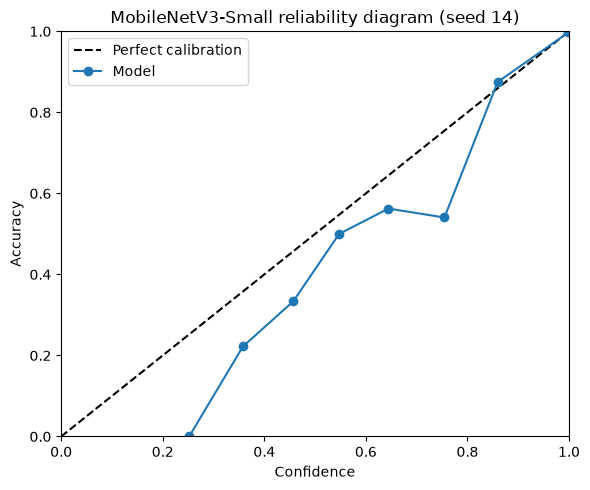

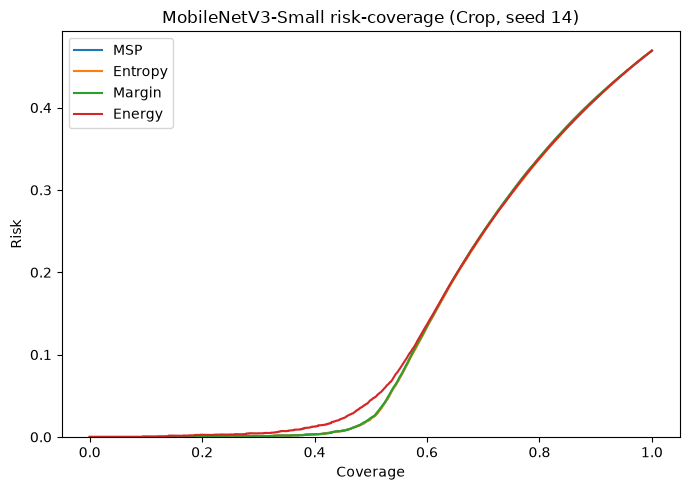

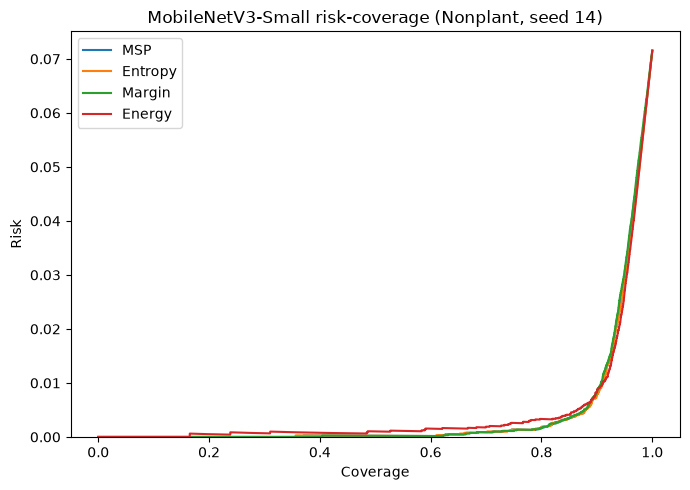

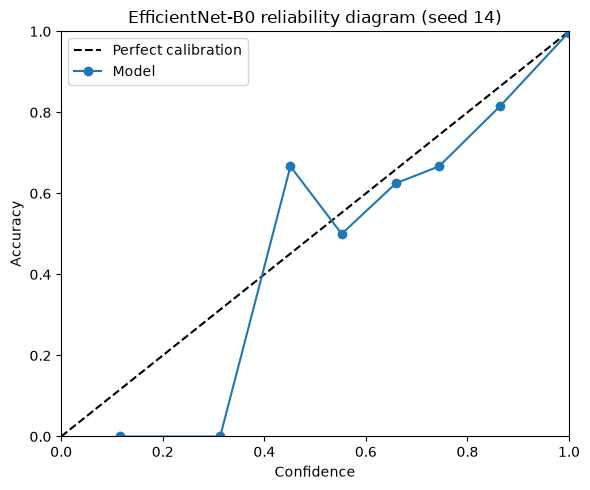

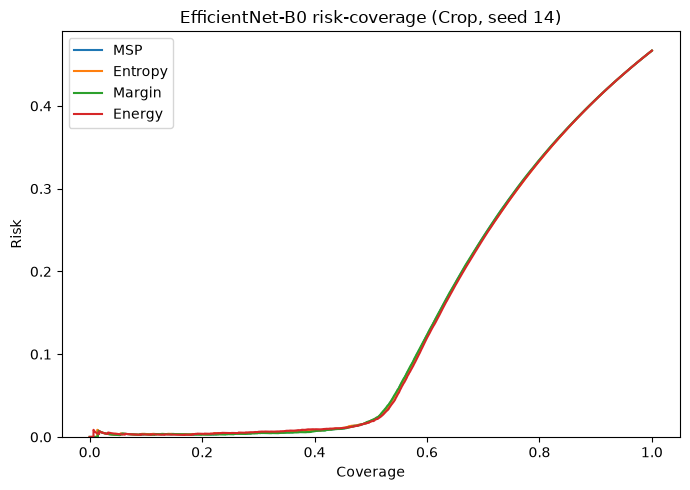

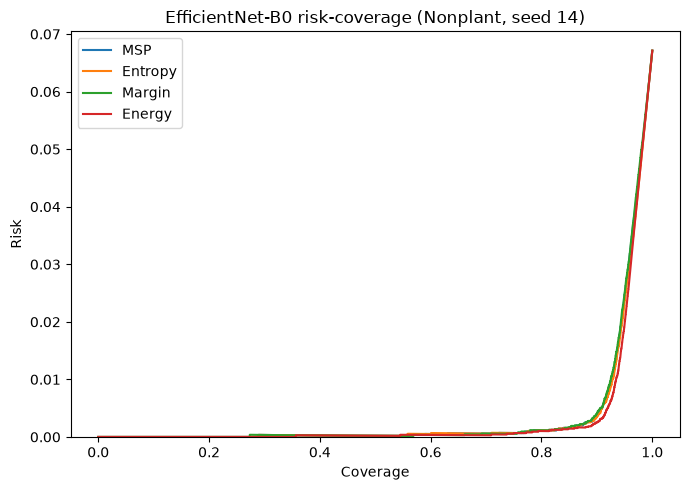

In [8]:
generate_final_evaluation_figures(14)


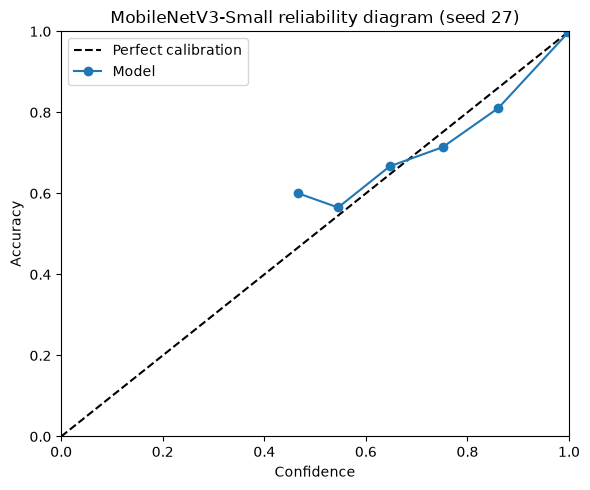

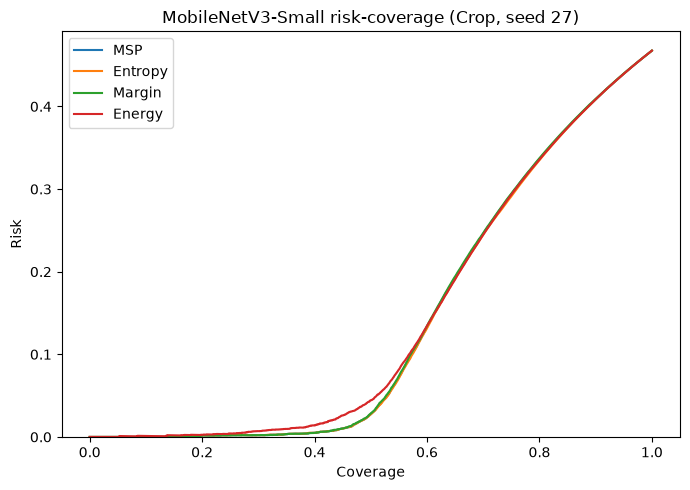

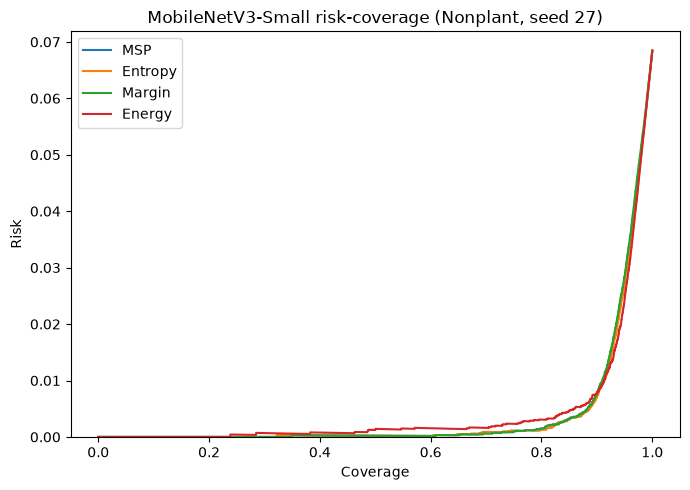

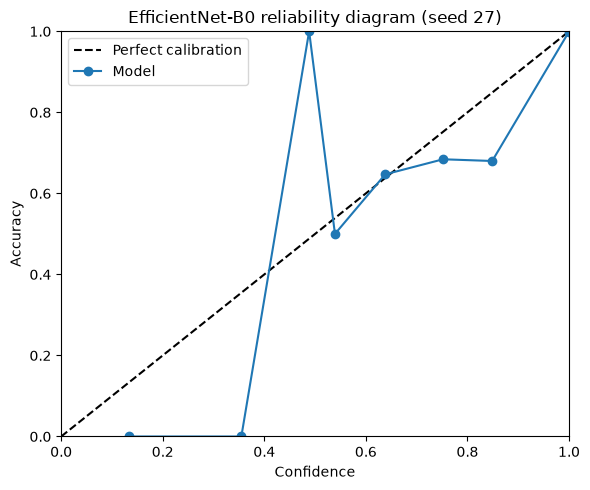

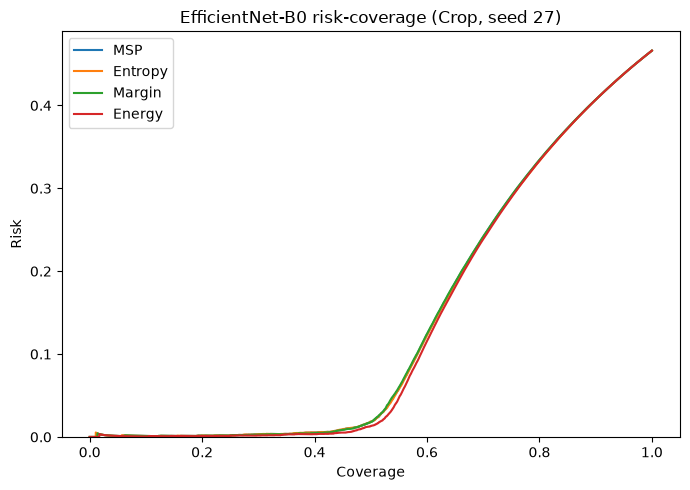

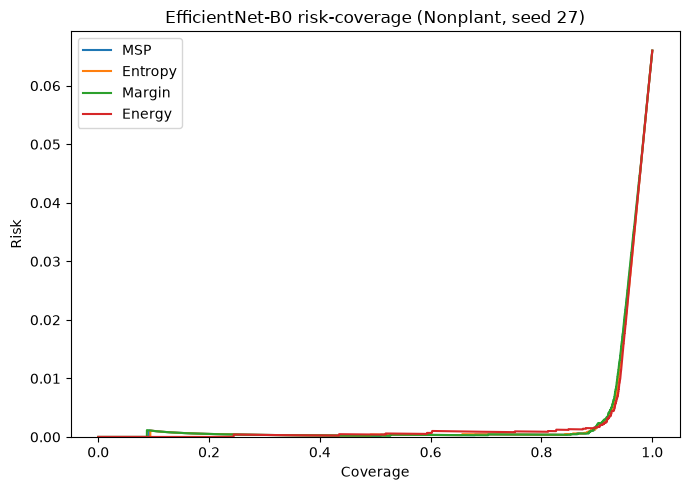

In [9]:
generate_final_evaluation_figures(27)


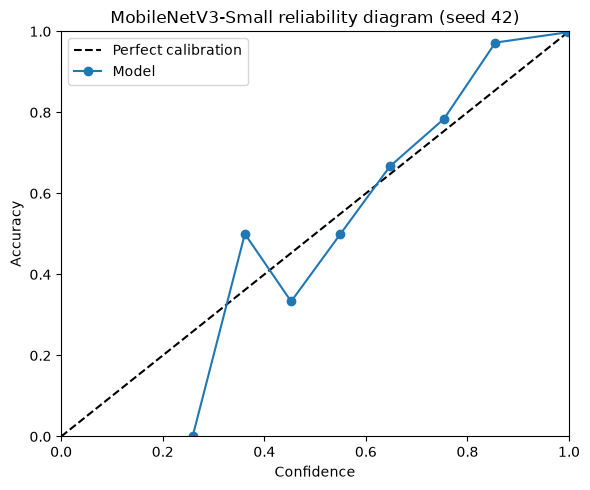

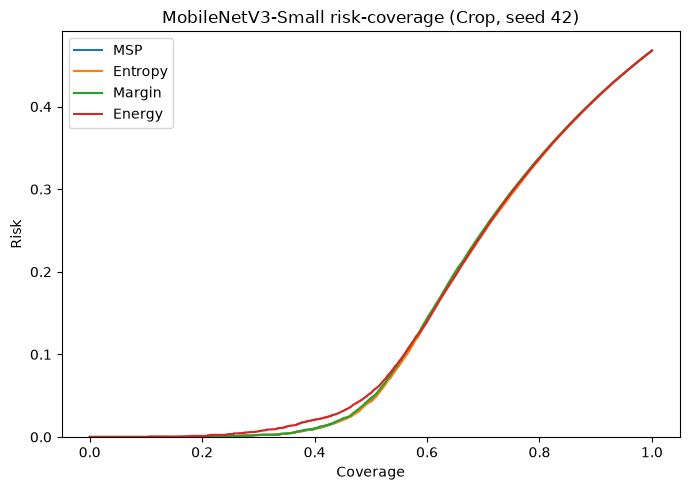

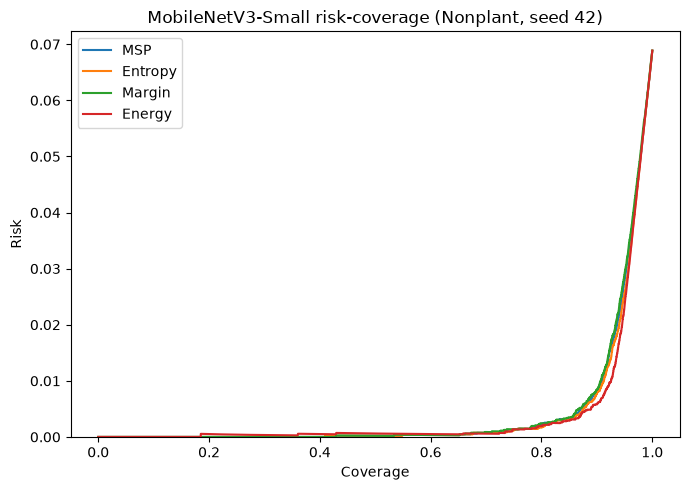

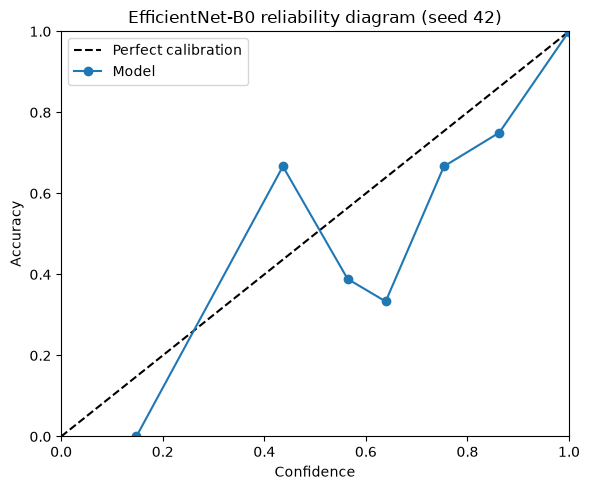

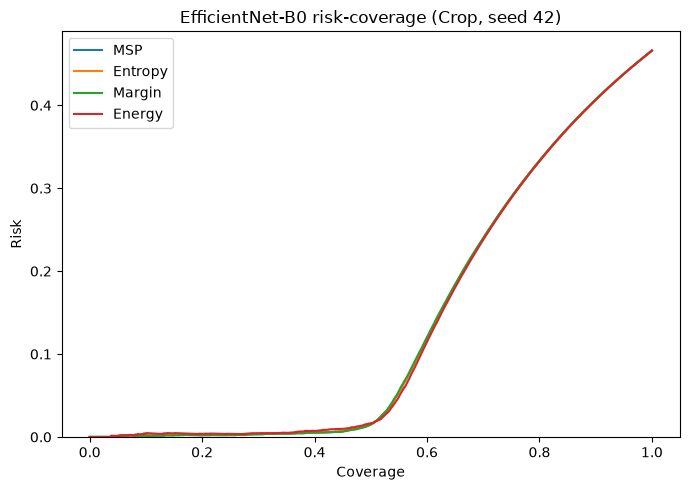

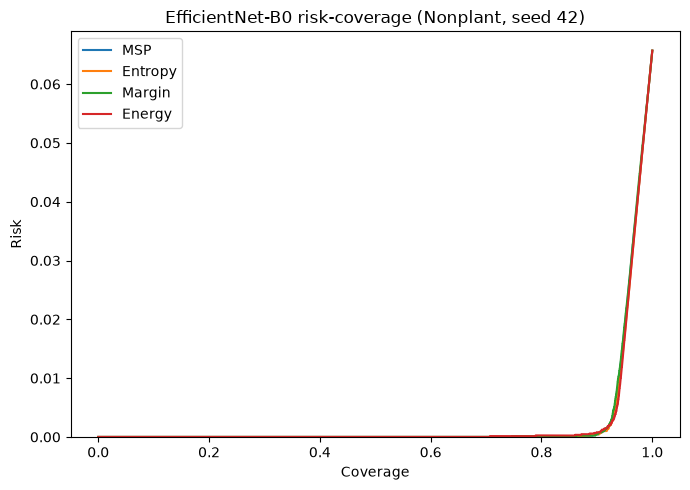

In [10]:
generate_final_evaluation_figures(42)
